# 01 · Data inventory and frame quality control

**Purpose.** Show what raw data we have, how it was captured, which frames are unusable and
why, and the room temperature during each session.

**Inputs.** `data/processed/manifest.parquet` (from `foodlens ingest` then `foodlens qc`),
`reports/tables/inventory.csv`, `reports/tables/qc_summary.csv`, `reports/qc_rejects.csv`.

**Outputs.** `reports/figures/qc_examples.png`, `reports/figures/temperature_sessions.png`.

**Run time.** About 10 s (it only reads the tables and a few photos). If the raw data or the
manifest is missing (e.g. a fresh clone), the notebook says so and stops showing results.

## How the photos were taken
A piece of raw chicken sits in a dark box. A phone takes one photo every ~60 s while the box
cycles through a **red, green and blue LED** (R, G, B, R, G, B, ...). Camera settings are fixed
(manual ISO and shutter) but white balance is automatic. Each folder (e.g. `exp1_D1A`) is one
**session**: one piece filmed continuously for 2-6 hours.

Every photo becomes one row of the **manifest** table. We never edit the original photos.

In [1]:
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
from IPython.display import Image, display  # noqa: E402

from foodlens.config import load_config  # noqa: E402
from foodlens.stages import manifest_path  # noqa: E402

cfg = load_config()
reports = cfg.path("reports_dir")
figures = reports / "figures"
HAVE_DATA = manifest_path(cfg).is_file() and cfg.path("raw_dir").is_dir()
if HAVE_DATA:
    man = pd.read_parquet(manifest_path(cfg))
    print(f"manifest: {len(man)} frames, {man['session_id'].nunique()} sessions")
else:
    print("No manifest/raw data: run `uv run foodlens ingest && uv run foodlens qc` first.")

manifest: 944 frames, 5 sessions


## Inventory per session
Start/end time, duration, number of frames per **scheduled** light and per light **measured
from the pixels**, the longest gap between photos, and the camera settings (one unique value
each means the settings never changed).

In [2]:
if HAVE_DATA:
    display(pd.read_csv(reports / "tables" / "inventory.csv").T)

,0,1,2,3,4
session_id,exp1_D1A,exp1_D1B,exp2_D2A,exp2_D2B,exp2_D3A
experiment,EXP-1,EXP-1,EXP-2,EXP-2,EXP-2
n_frames,132,118,169,181,344
n_ingest_reject,0,0,0,0,0
start,2026-08-28 12:19:50.765805+05:30,2026-08-28 14:32:24.511274+05:30,2026-09-01 11:03:59.661710+05:30,2026-09-01 13:59:39.536402+05:30,2026-09-02 08:17:30.669089+05:30
end,2026-08-28 14:30:51.843377+05:30,2026-08-28 16:29:25.445006+05:30,2026-09-01 13:52:32.796991+05:30,2026-09-01 16:59:41.076263+05:30,2026-09-02 14:00:33.444204+05:30
duration_h,2.183633,1.950259,2.809204,3.000428,5.717438
max_gap_s,60.125934,60.133066,91.562276,60.148893,60.154715
n_sched_BLUE,44,39,56,60,114
n_sched_GREEN,44,39,56,60,115


## Quality control (QC)
We do not trust the schedule: each frame's light is measured from its pixels.
- **E_DARK_FRAME**: the photo is black (the LED was off). In `exp1_D1A` the blue LED did not
  work until about 13:34, so 24 blue-slot photos are black.
- **E_MIXED_LIGHT**: no single colour dominates, e.g. the room light was switched on
  (the last `exp1_D1A` photo at 14:30).
- **W_BLUR** (warning only): far less sharp than the other photos of the same session and
  light, e.g. the camera refocused.

Rejected frames are kept in the manifest (with the reason) but not used for training.

In [3]:
if HAVE_DATA:
    display(pd.read_csv(reports / "tables" / "qc_summary.csv"))

,session_id,n_frames,ok,warn,reject,E_DARK_FRAME,E_MIXED_LIGHT,W_BLUR,usable
0,exp1_D1A,132,107,0,25,24,1,0,107
1,exp1_D1B,118,118,0,0,0,0,0,118
2,exp2_D2A,169,169,0,0,0,0,0,169
3,exp2_D2B,181,181,0,0,0,0,0,181
4,exp2_D3A,344,343,1,0,0,0,1,344
5,TOTAL,944,918,1,25,24,1,1,919


### One example per reason (contrast-stretched so the dark photos are visible)

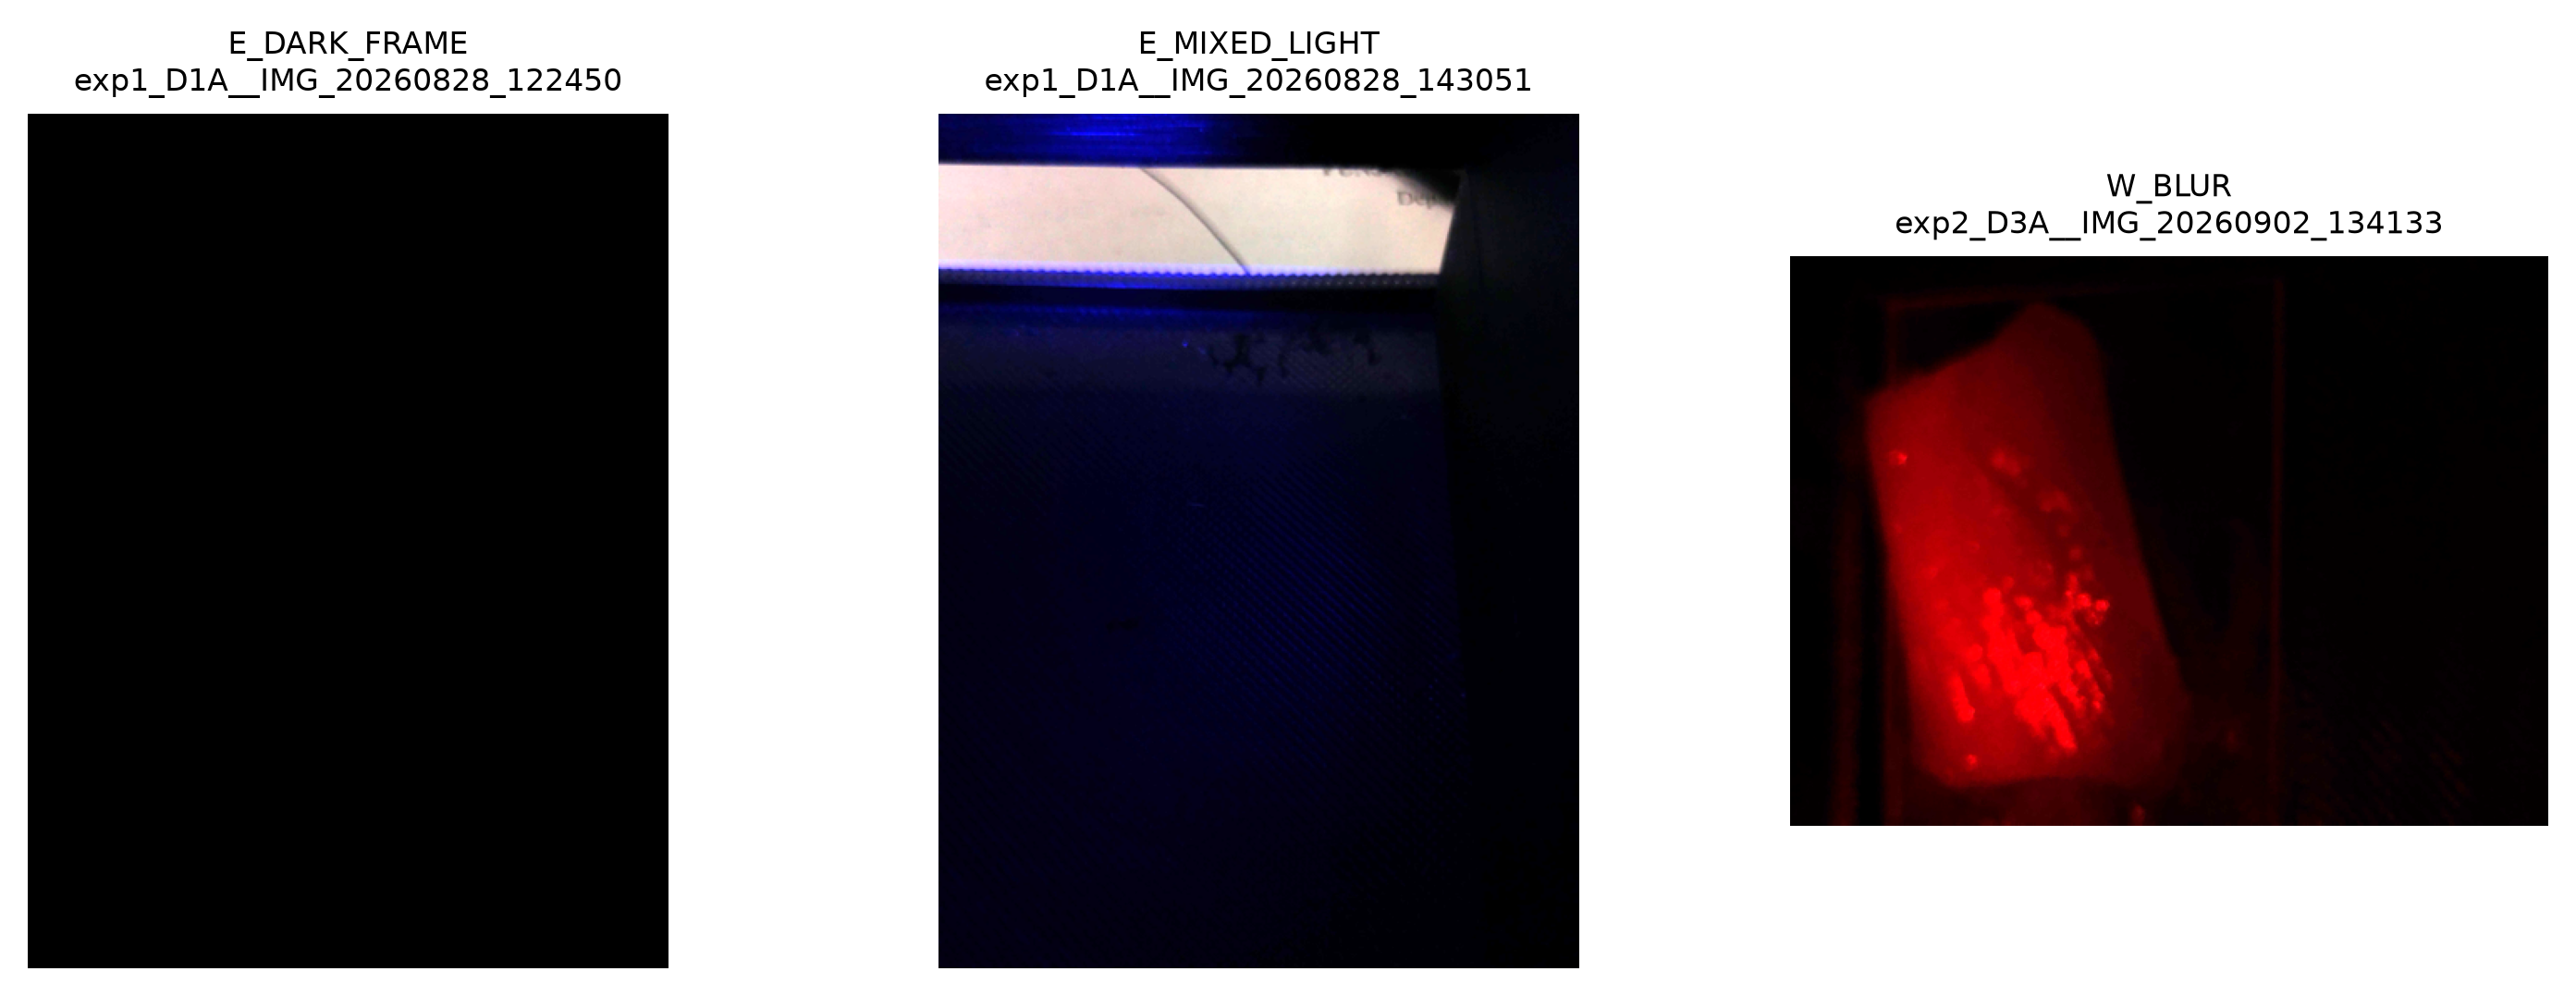

In [4]:
if HAVE_DATA:
    from foodlens.viz import show_examples

    flagged = man[man["qc_reasons"].fillna("") != ""]
    first = flagged.assign(reason=flagged["qc_reasons"].str.split(";").str[0])
    picks = first.groupby("reason").head(1).sort_values("reason")
    picks = picks[picks["path"].map(lambda p: (cfg.root / p).is_file())]
    fig = show_examples(
        [cfg.root / p for p in picks["path"]],
        [f"{r}\n{f}" for r, f in zip(picks["reason"], picks["frame_id"], strict=True)],
        cfg.vision.work_long_side // 2,
        "qc_examples",
        figures,
    )
    plt.close(fig)
    display(Image(filename=str(figures / "qc_examples.png"), width=900))

## Room temperature
Bacteria grow faster when it is warmer, so temperature matters for the age label later (P5).
We did not log temperature, so we use the hourly **weather archive** (Open-Meteo) for the
capture location, interpolated to each photo's time. This is outdoor air temperature; the
config value `thermal.indoor_offset_c` can correct it if indoor readings become available.

             min   max  mean
session_id                  
exp1_D1A    33.2  33.9  33.6
exp1_D1B    33.3  33.8  33.6
exp2_D2A    29.7  32.3  31.7
exp2_D2B    25.8  30.5  28.5
exp2_D3A    26.3  31.1  28.9


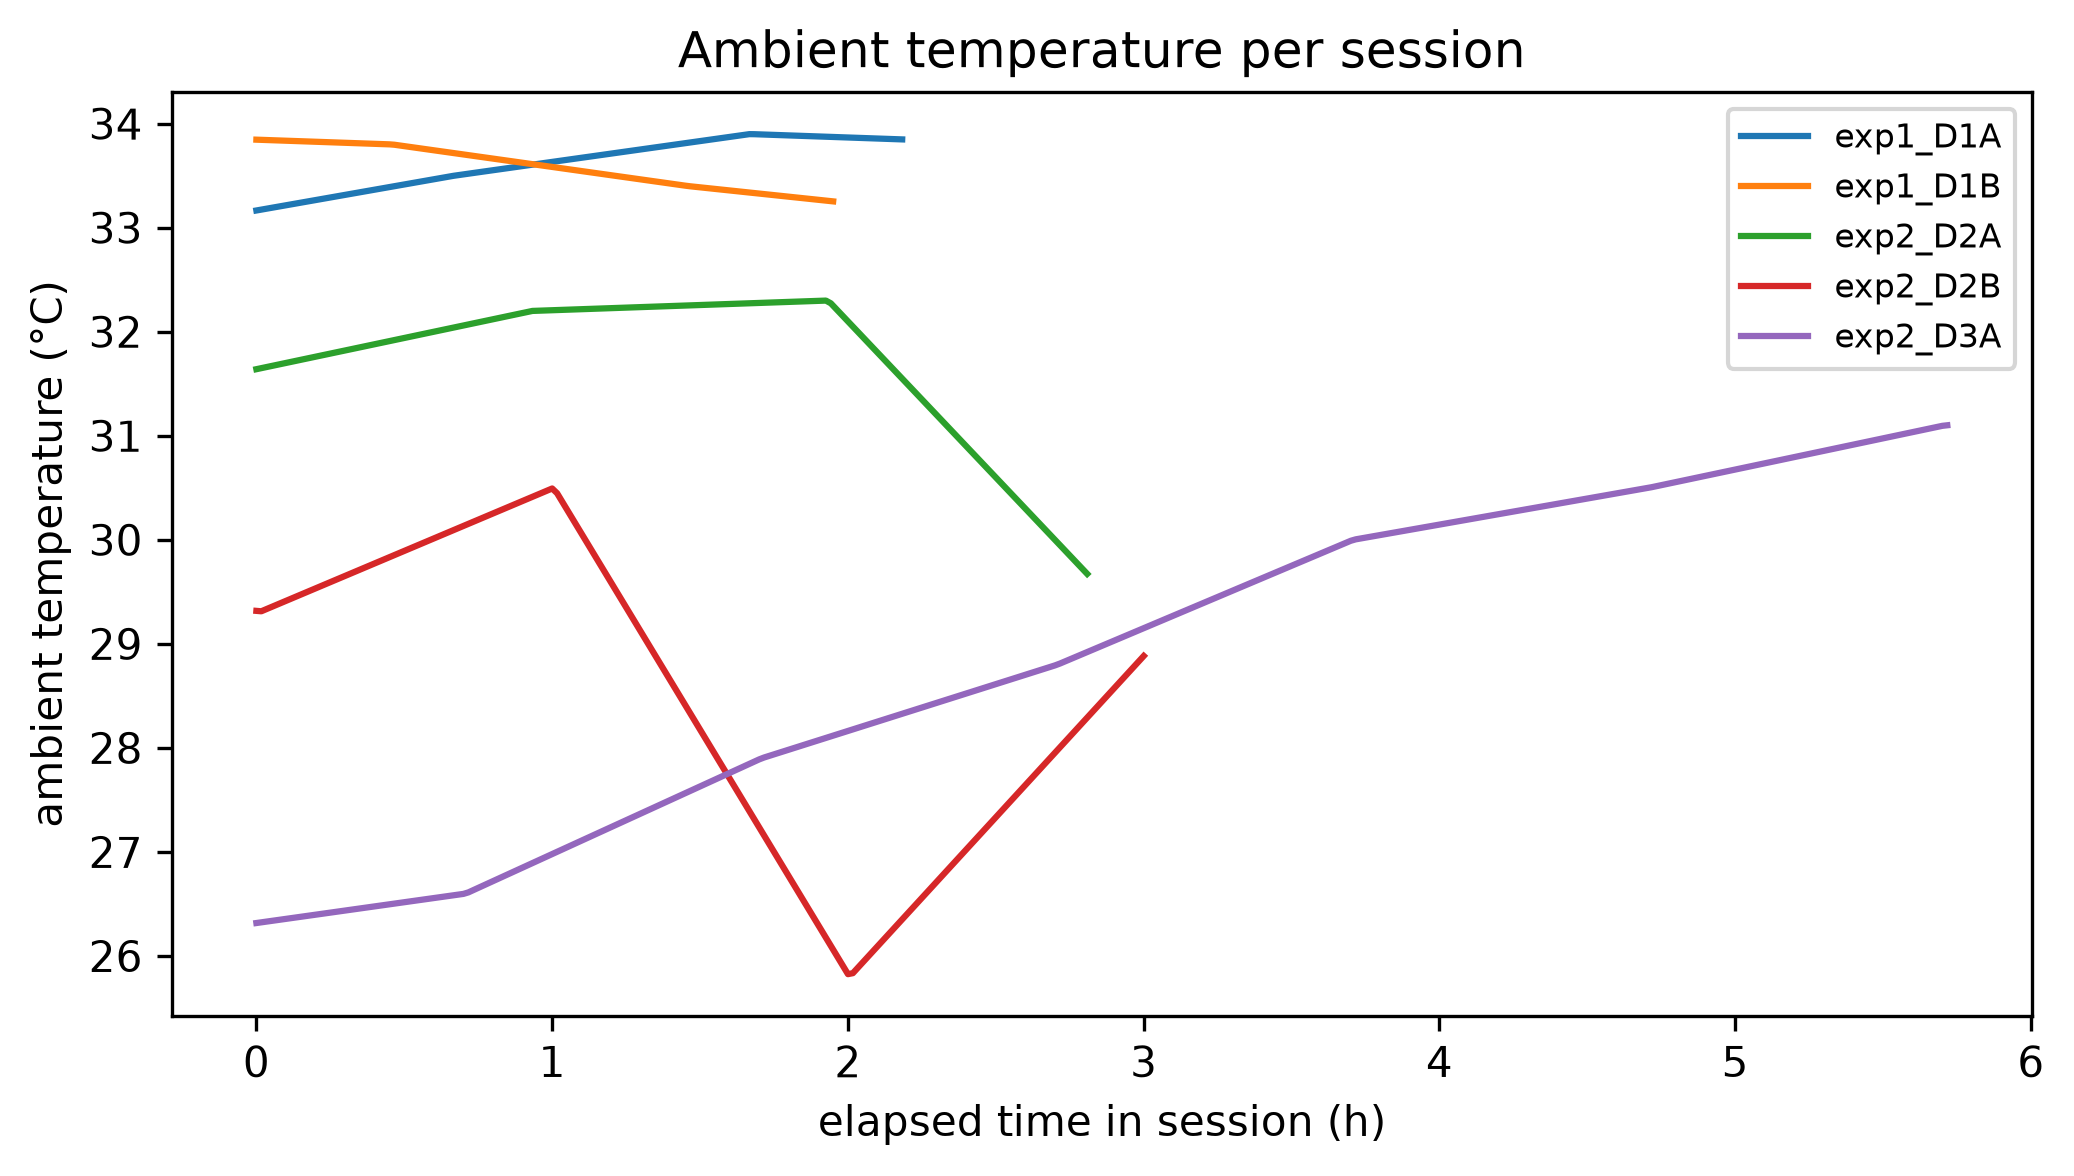

In [5]:
if HAVE_DATA:
    print(man.groupby("session_id")["temp_c"].agg(["min", "max", "mean"]).round(1))
    display(Image(filename=str(figures / "temperature_sessions.png"), width=700))

## Take-aways
- Use only frames with `qc_status` in {ok, warn}; the light column is the measured light.
- Scene-change detection (moved sample, lights on) is finished in P2 once the meat region is
  segmented; QC is re-run then.